# INX Future Inc. – Employee Performance Analysis

## 1. Project Objectives

1. To analyze employee performance ratings across different departments.
2. To identify the top three important factors associated with employee performance.
3. To perform exploratory data analysis (EDA) to discover patterns and trends in employee data.
4. To develop and evaluate machine learning models to predict employee performance ratings.
5. To identify areas where employee performance can be improved.
6. To provide data-driven recommendations to improve employee performance and organizational effectiveness.


## 2. Problem Statement

INX Future Inc. has experienced a decline in employee performance, an increase in service delivery escalations, and an 8-percentage-point decrease in client satisfaction.

The company needs to understand the factors associated with employee performance and identify opportunities for improvement. This project uses exploratory data analysis and machine learning techniques to analyze employee data, compare performance across departments, predict employee performance ratings, and provide data-driven recommendations to support better organizational decision-making.

## 3. Expected Outcomes

1. A clear understanding of employee performance across different departments.
2. Identification of the top three factors most important for predicting employee performance.
3. Insights into patterns and relationships between employee characteristics and performance ratings.
4. A trained and evaluated machine learning model for predicting employee performance ratings.
5. Identification of potential areas for employee performance improvement.
6. Actionable recommendations to support employee development, improve workplace effectiveness, and support better business decisions.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import pandas as pd

df = pd.read_excel(
    "INX_Future_Inc_Employee_Performance_CDS_Project2_Data_V1.8 (3).xls"
)

df.head()

,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,...,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,...,4,10,2,2,10,7,0,8,No,3
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,...,4,20,2,3,7,7,1,7,No,3
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,...,3,20,2,3,18,13,1,12,No,4
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,...,2,23,2,2,21,6,12,6,No,3
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,...,4,10,1,3,2,2,2,2,No,3


In [3]:
df.shape

(1200, 28)

In [4]:
df.columns

Index(['EmpNumber', 'Age', 'Gender', 'EducationBackground', 'MaritalStatus',
       'EmpDepartment', 'EmpJobRole', 'BusinessTravelFrequency',
       'DistanceFromHome', 'EmpEducationLevel', 'EmpEnvironmentSatisfaction',
       'EmpHourlyRate', 'EmpJobInvolvement', 'EmpJobLevel',
       'EmpJobSatisfaction', 'NumCompaniesWorked', 'OverTime',
       'EmpLastSalaryHikePercent', 'EmpRelationshipSatisfaction',
       'TotalWorkExperienceInYears', 'TrainingTimesLastYear',
       'EmpWorkLifeBalance', 'ExperienceYearsAtThisCompany',
       'ExperienceYearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager', 'Attrition', 'PerformanceRating'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   EmpNumber                     1200 non-null   object
 1   Age                           1200 non-null   int64 
 2   Gender                        1200 non-null   object
 3   EducationBackground           1200 non-null   object
 4   MaritalStatus                 1200 non-null   object
 5   EmpDepartment                 1200 non-null   object
 6   EmpJobRole                    1200 non-null   object
 7   BusinessTravelFrequency       1200 non-null   object
 8   DistanceFromHome              1200 non-null   int64 
 9   EmpEducationLevel             1200 non-null   int64 
 10  EmpEnvironmentSatisfaction    1200 non-null   int64 
 11  EmpHourlyRate                 1200 non-null   int64 
 12  EmpJobInvolvement             1200 non-null   int64 
 13  EmpJobLevel       

In [6]:
df.isnull().sum()

EmpNumber                       0
Age                             0
Gender                          0
EducationBackground             0
MaritalStatus                   0
EmpDepartment                   0
EmpJobRole                      0
BusinessTravelFrequency         0
DistanceFromHome                0
EmpEducationLevel               0
EmpEnvironmentSatisfaction      0
EmpHourlyRate                   0
EmpJobInvolvement               0
EmpJobLevel                     0
EmpJobSatisfaction              0
NumCompaniesWorked              0
OverTime                        0
EmpLastSalaryHikePercent        0
EmpRelationshipSatisfaction     0
TotalWorkExperienceInYears      0
TrainingTimesLastYear           0
EmpWorkLifeBalance              0
ExperienceYearsAtThisCompany    0
ExperienceYearsInCurrentRole    0
YearsSinceLastPromotion         0
YearsWithCurrManager            0
Attrition                       0
PerformanceRating               0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

# Exploratory Data Analysis (EDA)

## Performance Rating Distribution


In [8]:
df["PerformanceRating"].value_counts()

PerformanceRating
3    874
2    194
4    132
Name: count, dtype: int64

In [9]:
df["PerformanceRating"].value_counts(normalize=True) * 100

PerformanceRating
3    72.833333
2    16.166667
4    11.000000
Name: proportion, dtype: float64

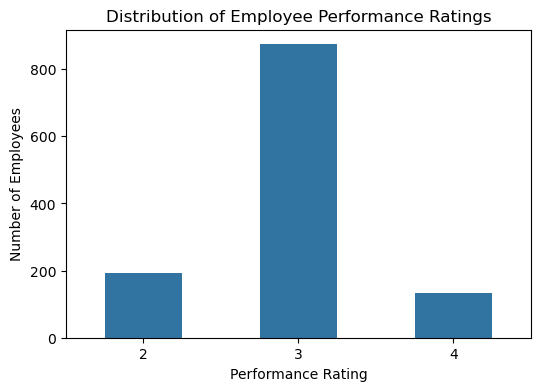

In [10]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="PerformanceRating", width=0.5)

plt.title("Distribution of Employee Performance Ratings")
plt.xlabel("Performance Rating")
plt.ylabel("Number of Employees")

plt.show()

## Department-wise Performance Analysis

In [11]:
df.groupby("EmpDepartment")["PerformanceRating"].mean().sort_values(ascending=False)

EmpDepartment
Development               3.085873
Data Science              3.050000
Human Resources           2.925926
Research & Development    2.921283
Sales                     2.860590
Finance                   2.775510
Name: PerformanceRating, dtype: float64

## Average Performance Rating by Department

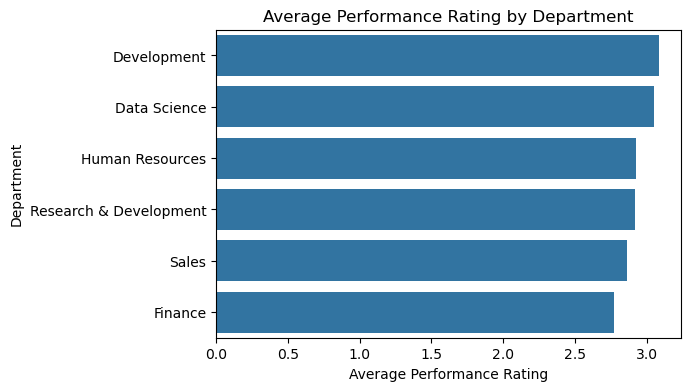

In [12]:
department_performance = (
    df.groupby("EmpDepartment")["PerformanceRating"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(6,4))

sns.barplot(
    x=department_performance.values,
    y=department_performance.index
)

plt.title("Average Performance Rating by Department")
plt.xlabel("Average Performance Rating")
plt.ylabel("Department")

plt.show()

##  Employee Demographics Analysis

### Age vs Performance Rating

In [13]:
df.groupby("Age")["PerformanceRating"].mean().sort_values(ascending=False)

Age
19    3.500000
60    3.333333
18    3.125000
23    3.111111
42    3.083333
51    3.071429
28    3.051282
30    3.047619
38    3.041667
26    3.030303
45    3.027778
37    3.024390
32    3.021739
56    3.000000
20    3.000000
50    3.000000
36    2.983333
41    2.968750
40    2.956522
55    2.941176
22    2.933333
27    2.930233
31    2.929825
25    2.916667
58    2.909091
49    2.904762
34    2.901408
35    2.890625
43    2.884615
29    2.882353
48    2.875000
39    2.870968
33    2.869565
52    2.866667
47    2.850000
46    2.833333
59    2.833333
21    2.818182
54    2.812500
44    2.800000
24    2.800000
57    2.750000
53    2.733333
Name: PerformanceRating, dtype: float64

In [14]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65"]
)

df.groupby("Age_Group", observed=True)["PerformanceRating"].mean() 

Age_Group
18-25    2.970297
26-35    2.945122
36-45    2.974093
46-55    2.892473
56-65    2.942857
Name: PerformanceRating, dtype: float64

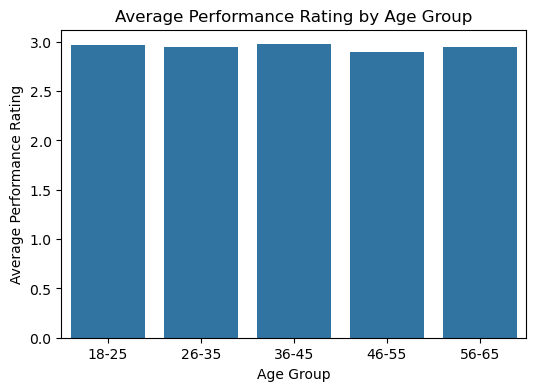

In [15]:
age_performance = df.groupby(
    "Age_Group", observed=True
)["PerformanceRating"].mean()

plt.figure(figsize=(6,4))

sns.barplot(
    x=age_performance.index,
    y=age_performance.values
)

plt.title("Average Performance Rating by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Performance Rating")

plt.show()

The average performance rating is relatively similar across all age groups. The 46-55 age group has the lowest average performance rating, while the 18-25 and 36-45 age groups have the highest average ratings.

Overall, age does not appear to be a strong differentiating factor in employee performance based on average performance ratings alone.

### Gender vs Performance Rating

In [16]:
df.groupby("Gender")["PerformanceRating"].mean().sort_values(ascending=False)

Gender
Female    2.949474
Male      2.947586
Name: PerformanceRating, dtype: float64

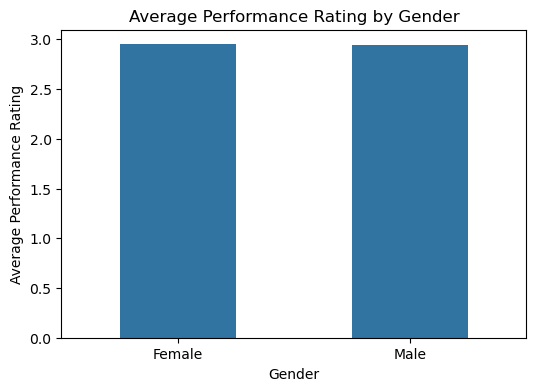

In [17]:
gender_performance = df.groupby("Gender")["PerformanceRating"].mean()

plt.figure(figsize=(6,4))

sns.barplot(
    x=gender_performance.index,
    y=gender_performance.values,
    width=0.5
)

plt.title("Average Performance Rating by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Performance Rating")

plt.show()

### Education Background vs Performance Rating

In [18]:
education_performance = (
    df.groupby("EducationBackground")["PerformanceRating"]
    .mean()
    .sort_values(ascending=False)
)

education_performance

EducationBackground
Other               3.060606
Life Sciences       2.957317
Human Resources     2.952381
Medical             2.940104
Technical Degree    2.940000
Marketing           2.890511
Name: PerformanceRating, dtype: float64

### Average Performance Rating by Education Background

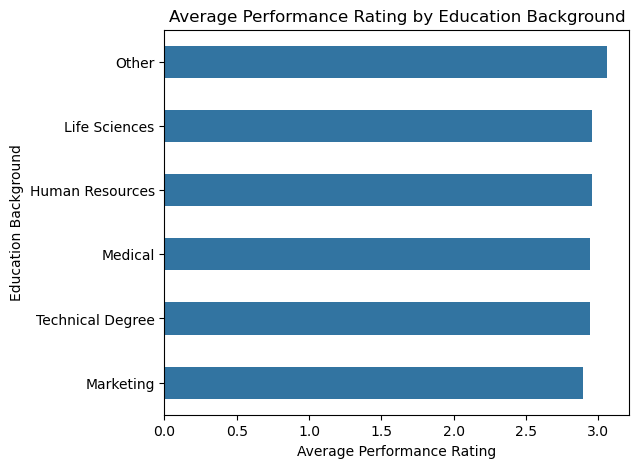

In [19]:
plt.figure(figsize=(6,5))

sns.barplot(
    x=education_performance.values,
    y=education_performance.index,
    width=0.5
)

plt.title("Average Performance Rating by Education Background")
plt.xlabel("Average Performance Rating")
plt.ylabel("Education Background")

plt.show()

###  Marital Status vs Performance Rating

In [20]:
marital_performance = (
    df.groupby("MaritalStatus")["PerformanceRating"]
    .mean()
    .sort_values(ascending=False)
)

marital_performance

MaritalStatus
Single      2.984375
Divorced    2.958955
Married     2.917883
Name: PerformanceRating, dtype: float64

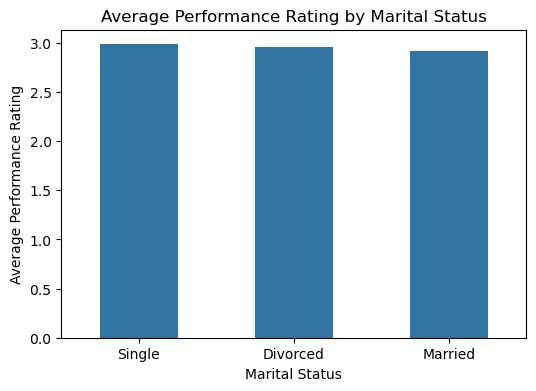

In [21]:
plt.figure(figsize=(6,4))

sns.barplot(
    x=marital_performance.index,
    y=marital_performance.values,
    width=0.5
)

plt.title("Average Performance Rating by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Average Performance Rating")

plt.show()

## Job and Work-related Factors

###  Job Role vs Performance Rating

In [22]:
jobrole_performance = (
    df.groupby("EmpJobRole")["PerformanceRating"]
    .mean()
    .sort_values(ascending=False)
)

jobrole_performance

EmpJobRole
Business Analyst             3.187500
Developer                    3.105932
Technical Lead               3.078947
Data Scientist               3.050000
Delivery Manager             3.000000
Senior Developer             3.000000
Technical Architect          3.000000
Manufacturing Director       2.969697
Research Scientist           2.961039
Manager                      2.960784
Manager R&D                  2.936170
Human Resources              2.911111
Research Director            2.894737
Sales Representative         2.869565
Laboratory Technician        2.859375
Sales Executive              2.855556
Healthcare Representative    2.848485
Senior Manager R&D           2.800000
Finance Manager              2.775510
Name: PerformanceRating, dtype: float64

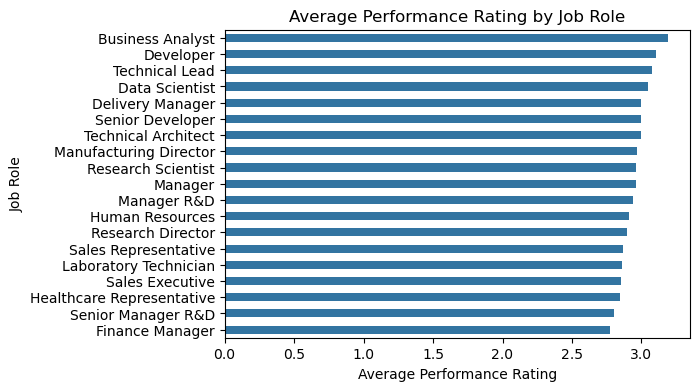

In [23]:
plt.figure(figsize=(6,4))

sns.barplot(
    x=jobrole_performance.values,
    y=jobrole_performance.index,
    width=0.5
)

plt.title("Average Performance Rating by Job Role")
plt.xlabel("Average Performance Rating")
plt.ylabel("Job Role")

plt.show()

###  Job Level vs Performance Rating

In [24]:
joblevel_performance = (
    df.groupby("EmpJobLevel")["PerformanceRating"]
    .mean()
    .sort_values(ascending=False)
)

joblevel_performance

EmpJobLevel
1    2.993182
2    2.947846
3    2.890173
4    2.888889
5    2.875000
Name: PerformanceRating, dtype: float64

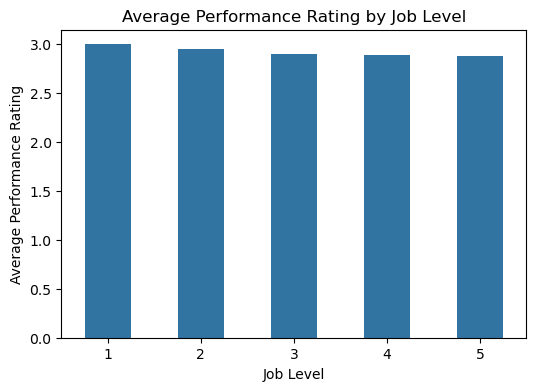

In [25]:
plt.figure(figsize=(6,4))

sns.barplot(
    x=joblevel_performance.index.astype(str),
    y=joblevel_performance.values,
    width=0.5
)

plt.title("Average Performance Rating by Job Level")
plt.xlabel("Job Level")
plt.ylabel("Average Performance Rating")

plt.show()

### Job Involvement vs Performance Rating

In [26]:
df.groupby("EmpJobInvolvement")["PerformanceRating"].mean().sort_values(ascending=False)

EmpJobInvolvement
2    2.959184
1    2.957143
4    2.946429
3    2.943370
Name: PerformanceRating, dtype: float64

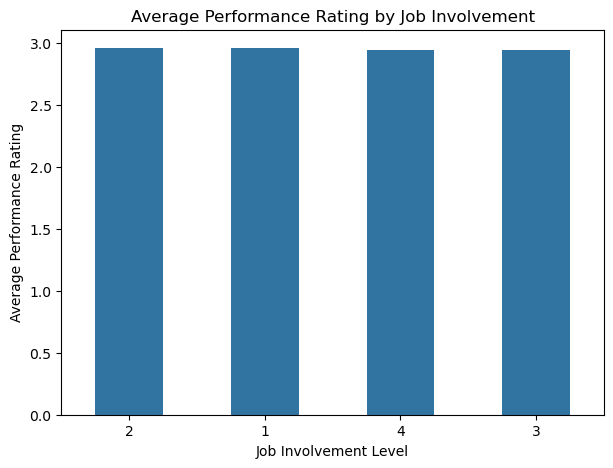

In [27]:
jobinvolvement_performance = (
    df.groupby("EmpJobInvolvement")["PerformanceRating"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(7,5))

sns.barplot(
    x=jobinvolvement_performance.index.astype(str),
    y=jobinvolvement_performance.values,
    width=0.5
)

plt.title("Average Performance Rating by Job Involvement")
plt.xlabel("Job Involvement Level")
plt.ylabel("Average Performance Rating")

plt.show()

### Job Satisfaction vs Performance Rating

In [28]:
jobsatisfaction_performance = (
    df.groupby("EmpJobSatisfaction")["PerformanceRating"]
    .mean()
    .sort_values(ascending=False)
)

jobsatisfaction_performance

EmpJobSatisfaction
4    2.978836
1    2.969697
2    2.953586
3    2.898305
Name: PerformanceRating, dtype: float64

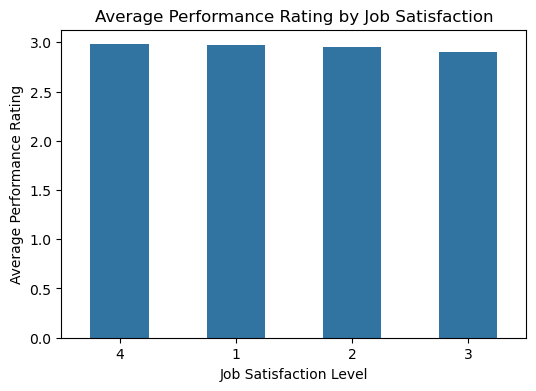

In [29]:
plt.figure(figsize=(6,4))

sns.barplot(
    x=jobsatisfaction_performance.index.astype(str),
    y=jobsatisfaction_performance.values,
    width=0.5
)

plt.title("Average Performance Rating by Job Satisfaction")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Average Performance Rating")

plt.show()

### Overtime vs Performance Rating

In [30]:
overtime_performance = (
    df.groupby("OverTime")["PerformanceRating"]
    .mean()
    .sort_values(ascending=False)
)

overtime_performance

OverTime
Yes    2.988669
No     2.931523
Name: PerformanceRating, dtype: float64

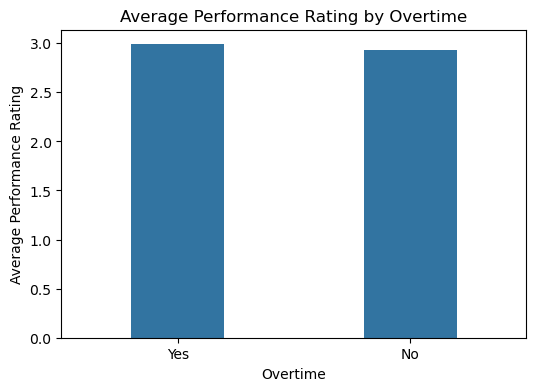

In [31]:
plt.figure(figsize=(6,4))

sns.barplot(
    x=overtime_performance.index,
    y=overtime_performance.values,
    width=0.4
)

plt.title("Average Performance Rating by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Average Performance Rating")
plt.show()

###  Business Travel Frequency vs Performance Rating

In [32]:
travel_performance = (
    df.groupby("BusinessTravelFrequency")["PerformanceRating"]
    .mean()
    .sort_values(ascending=False)
)

travel_performance

BusinessTravelFrequency
Non-Travel           2.977273
Travel_Frequently    2.972973
Travel_Rarely        2.937352
Name: PerformanceRating, dtype: float64

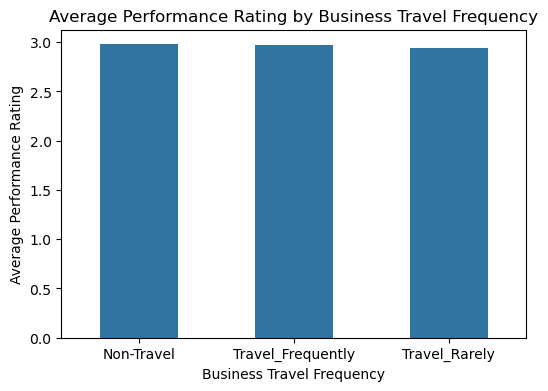

In [33]:
plt.figure(figsize=(6,4))

sns.barplot(
    x=travel_performance.index,
    y=travel_performance.values,
    width=0.5
)

plt.title("Average Performance Rating by Business Travel Frequency")
plt.xlabel("Business Travel Frequency")
plt.ylabel("Average Performance Rating")
plt.show()

###  Environment Satisfaction vs Performance Rating

In [34]:
environment_performance = (
    df.groupby("EmpEnvironmentSatisfaction")["PerformanceRating"]
    .mean()
    .sort_values(ascending=False)
)

environment_performance

EmpEnvironmentSatisfaction
3    3.138965
4    3.132964
1    2.665217
2    2.652893
Name: PerformanceRating, dtype: float64

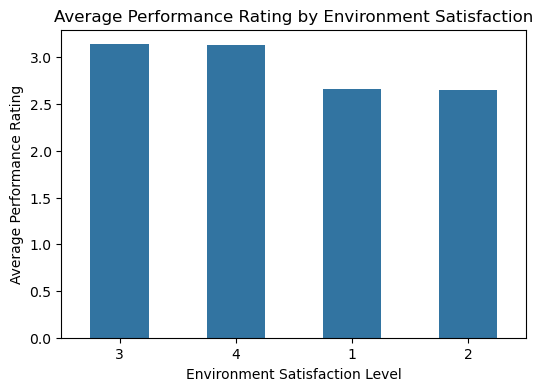

In [35]:
plt.figure(figsize=(6,4))

sns.barplot(
    x=environment_performance.index.astype(str),
    y=environment_performance.values,
    width=0.5
)

plt.title("Average Performance Rating by Environment Satisfaction")
plt.xlabel("Environment Satisfaction Level")
plt.ylabel("Average Performance Rating")
plt.show()

###  Relationship Satisfaction vs Performance Rating

In [36]:
relationship_performance = (
    df.groupby("EmpRelationshipSatisfaction")["PerformanceRating"]
    .mean()
    .sort_values(ascending=False)
)

relationship_performance

EmpRelationshipSatisfaction
3    2.970976
2    2.955466
1    2.949772
4    2.918310
Name: PerformanceRating, dtype: float64

###  Total Work Experience vs Performance Rating

In [37]:
experience_performance = (
    df.groupby("TotalWorkExperienceInYears")["PerformanceRating"]
    .mean()
    .sort_index()
)

experience_performance

TotalWorkExperienceInYears
0     3.100000
1     3.200000
2     2.884615
3     2.823529
4     2.862745
5     3.014085
6     2.885714
7     3.032787
8     3.082353
9     2.974026
10    2.899371
11    3.000000
12    3.054054
13    2.939394
14    2.846154
15    2.676471
16    2.906250
17    2.958333
18    2.952381
19    3.100000
20    2.960000
21    2.857143
22    2.944444
23    2.823529
24    2.769231
25    2.916667
26    2.769231
27    2.666667
28    2.769231
29    3.000000
30    3.000000
31    3.142857
32    3.125000
33    2.714286
34    3.200000
35    3.000000
36    3.000000
37    2.333333
38    3.000000
40    3.000000
Name: PerformanceRating, dtype: float64

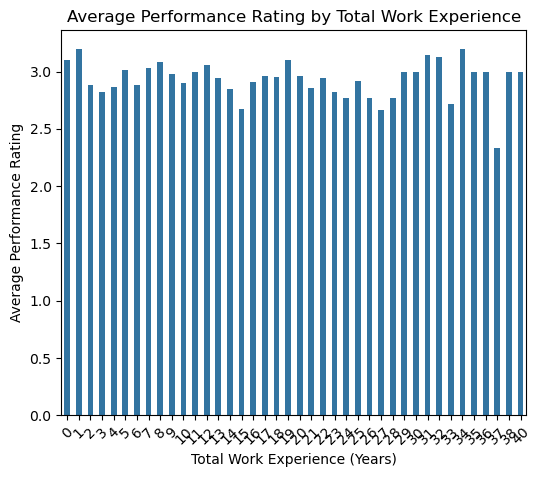

In [38]:
plt.figure(figsize=(6,5))

sns.barplot(
    x=experience_performance.index,
    y=experience_performance.values,
    width=0.5
)

plt.title("Average Performance Rating by Total Work Experience")
plt.xlabel("Total Work Experience (Years)")
plt.ylabel("Average Performance Rating")
plt.xticks(rotation=45)
plt.show()

### Training Times Last Year vs Performance Rating

In [39]:
training_performance = (
    df.groupby("TrainingTimesLastYear")["PerformanceRating"]
    .mean()
    .sort_values(ascending=False)
)

training_performance

TrainingTimesLastYear
3    2.975787
2    2.948315
1    2.946429
5    2.938776
4    2.918367
6    2.869565
0    2.863636
Name: PerformanceRating, dtype: float64

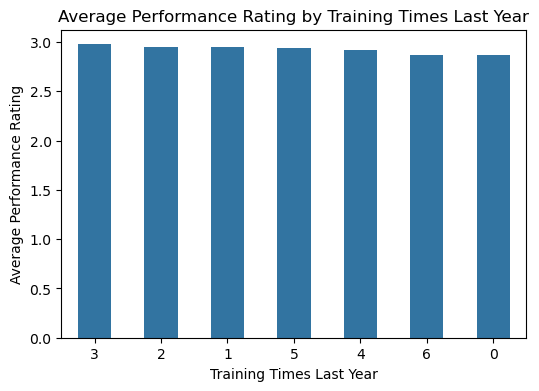

In [40]:
plt.figure(figsize=(6,4))

sns.barplot(
    x=training_performance.index.astype(str),
    y=training_performance.values,
    width=0.5
)

plt.title("Average Performance Rating by Training Times Last Year")
plt.xlabel("Training Times Last Year")
plt.ylabel("Average Performance Rating")
plt.show()

###  Work-Life Balance vs Performance Rating

In [41]:
worklife_performance = (
    df.groupby("EmpWorkLifeBalance")["PerformanceRating"]
    .mean()
    .sort_values(ascending=False)
)

worklife_performance

EmpWorkLifeBalance
4    3.121739
3    2.950481
2    2.918367
1    2.750000
Name: PerformanceRating, dtype: float64

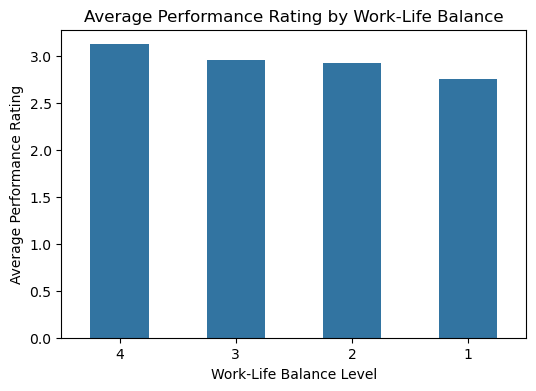

In [42]:
plt.figure(figsize=(6,4))

sns.barplot(
    x=worklife_performance.index.astype(str),
    y=worklife_performance.values,
    width=0.5
)

plt.title("Average Performance Rating by Work-Life Balance")
plt.xlabel("Work-Life Balance Level")
plt.ylabel("Average Performance Rating")
plt.show()

### Experience at Current Company vs Performance Rating

In [43]:
company_experience_performance = (
    df.groupby("ExperienceYearsAtThisCompany")["PerformanceRating"]
    .mean()
    .sort_index()
)

company_experience_performance

ExperienceYearsAtThisCompany
0     3.166667
1     3.173913
2     2.728972
3     2.990476
4     2.863636
5     3.052632
6     3.060606
7     2.958904
8     3.031746
9     2.893939
10    2.810000
11    2.888889
12    2.714286
13    2.888889
14    2.714286
15    2.705882
16    3.000000
17    3.000000
18    2.727273
19    2.818182
20    2.809524
21    2.714286
22    2.916667
23    4.000000
24    2.333333
25    2.500000
26    3.500000
27    3.000000
29    3.500000
30    2.000000
31    3.000000
32    2.333333
33    2.800000
34    4.000000
36    3.500000
37    3.000000
40    3.000000
Name: PerformanceRating, dtype: float64

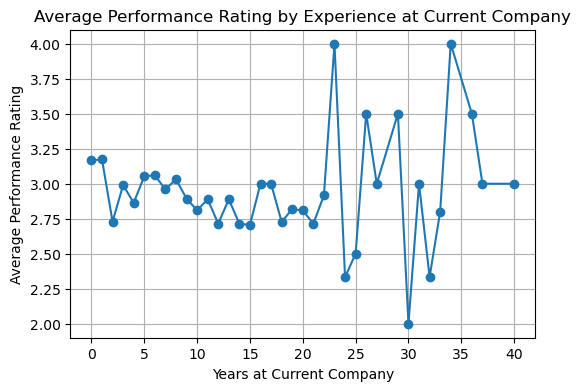

In [44]:
plt.figure(figsize=(6,4))

plt.plot(
    company_experience_performance.index,
    company_experience_performance.values,
    marker="o"
)

plt.title("Average Performance Rating by Experience at Current Company")
plt.xlabel("Years at Current Company")
plt.ylabel("Average Performance Rating")
plt.grid(True)
plt.show()

### Experience in Current Role vs Performance Rating

In [45]:
role_experience_performance = (
    df.groupby("ExperienceYearsInCurrentRole")["PerformanceRating"]
    .mean()
    .sort_index()
)

role_experience_performance

ExperienceYearsInCurrentRole
0     3.168421
1     3.086957
2     2.887789
3     2.934579
4     2.956522
5     3.137931
6     3.033333
7     2.920455
8     2.769231
9     2.746032
10    2.760000
11    3.055556
12    3.285714
13    3.200000
14    2.600000
15    3.250000
16    2.285714
17    2.666667
18    3.000000
Name: PerformanceRating, dtype: float64

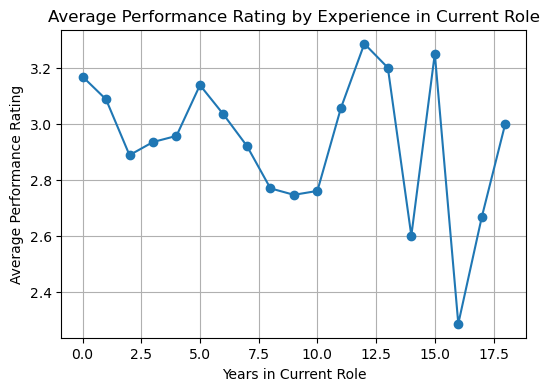

In [46]:
plt.figure(figsize=(6,4))

plt.plot(
    role_experience_performance.index,
    role_experience_performance.values,
    marker="o"
)

plt.title("Average Performance Rating by Experience in Current Role")
plt.xlabel("Years in Current Role")
plt.ylabel("Average Performance Rating")
plt.grid(True)
plt.show()

### Years Since Last Promotion vs Performance Rating

In [47]:
promotion_performance = (
    df.groupby("YearsSinceLastPromotion")["PerformanceRating"]
    .mean()
    .sort_index()
)

promotion_performance

YearsSinceLastPromotion
0     3.123667
1     2.898990
2     2.763780
3     2.777778
4     2.773585
5     2.828571
6     2.833333
7     2.854839
8     2.545455
9     2.687500
10    2.600000
11    2.826087
12    2.666667
13    3.125000
14    3.000000
15    2.909091
Name: PerformanceRating, dtype: float64

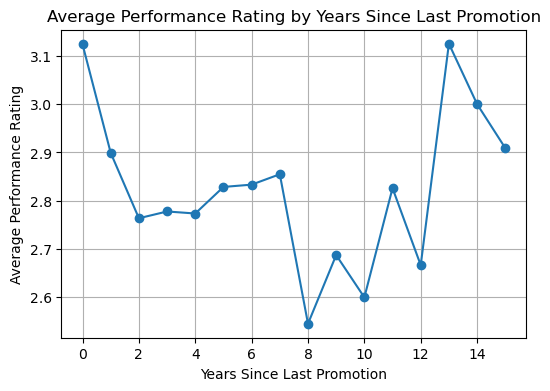

In [48]:
promotion_performance = (
    df.groupby("YearsSinceLastPromotion")["PerformanceRating"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(6,4))
plt.plot(
    promotion_performance.index,
    promotion_performance.values,
    marker="o"
)
plt.title("Average Performance Rating by Years Since Last Promotion")
plt.xlabel("Years Since Last Promotion")
plt.ylabel("Average Performance Rating")
plt.grid(True)
plt.show()

## Years With Current Manager vs Performance Rating

In [49]:
manager_experience_performance = (
    df.groupby("YearsWithCurrManager")["PerformanceRating"]
    .mean()
    .sort_index()
)

manager_experience_performance

YearsWithCurrManager
0     3.134884
1     2.910448
2     2.882562
3     2.951456
4     3.094118
5     2.961538
6     2.892857
7     2.909091
8     2.850575
9     2.886792
10    2.636364
11    3.000000
12    2.642857
13    2.700000
14    2.500000
15    3.000000
16    3.000000
17    3.166667
Name: PerformanceRating, dtype: float64

In [50]:
manager_experience_performance = (
    df.groupby("YearsWithCurrManager")["PerformanceRating"]
    .mean()
    .sort_index()
)

manager_experience_performance

YearsWithCurrManager
0     3.134884
1     2.910448
2     2.882562
3     2.951456
4     3.094118
5     2.961538
6     2.892857
7     2.909091
8     2.850575
9     2.886792
10    2.636364
11    3.000000
12    2.642857
13    2.700000
14    2.500000
15    3.000000
16    3.000000
17    3.166667
Name: PerformanceRating, dtype: float64

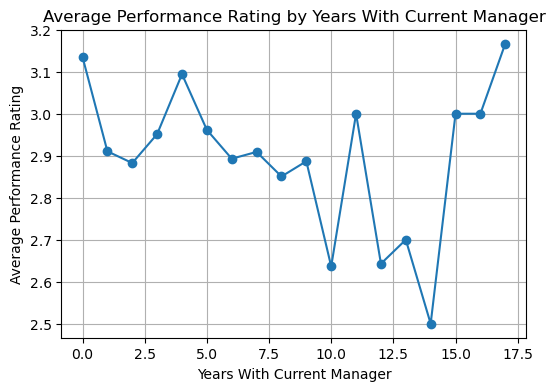

In [51]:
manager_experience_performance = (
    df.groupby("YearsWithCurrManager")["PerformanceRating"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(6,4))
plt.plot(
    manager_experience_performance.index,
    manager_experience_performance.values,
    marker="o"
)
plt.title("Average Performance Rating by Years With Current Manager")
plt.xlabel("Years With Current Manager")
plt.ylabel("Average Performance Rating")
plt.grid(True)
plt.show()

###  Employee Last Salary Hike vs Performance Rating

In [52]:
salary_hike_performance = (
    df.groupby("EmpLastSalaryHikePercent")["PerformanceRating"]
    .mean()
    .sort_index()
)

salary_hike_performance

EmpLastSalaryHikePercent
11    2.840237
12    2.819355
13    2.857143
14    2.860465
15    2.914634
16    2.852941
17    2.910448
18    2.863014
19    2.873016
20    3.360000
21    3.588235
22    3.425532
23    3.523810
24    3.500000
25    3.307692
Name: PerformanceRating, dtype: float64

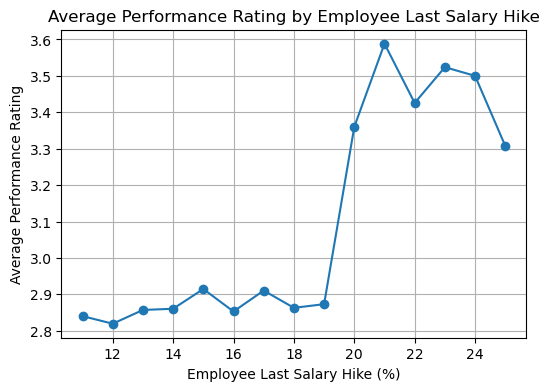

In [53]:
plt.figure(figsize=(6,4))

plt.plot(
    salary_hike_performance.index,
    salary_hike_performance.values,
    marker="o"
)

plt.title("Average Performance Rating by Employee Last Salary Hike")
plt.xlabel("Employee Last Salary Hike (%)")
plt.ylabel("Average Performance Rating")
plt.grid(True)
plt.show()

### Distance From Home vs Performance Rating

In [54]:
distance_performance = (
    df.groupby("DistanceFromHome")["PerformanceRating"]
    .mean()
    .sort_index()
)

distance_performance

DistanceFromHome
1     2.958824
2     2.956522
3     3.029851
4     2.980392
5     2.925926
6     2.934783
7     3.000000
8     2.942029
9     2.893939
10    3.000000
11    3.040000
12    2.937500
13    2.857143
14    2.941176
15    2.764706
16    3.160000
17    3.000000
18    2.750000
19    2.944444
20    2.789474
21    2.933333
22    2.823529
23    2.909091
24    2.913043
25    3.000000
26    2.909091
27    3.000000
28    2.900000
29    2.826087
Name: PerformanceRating, dtype: float64

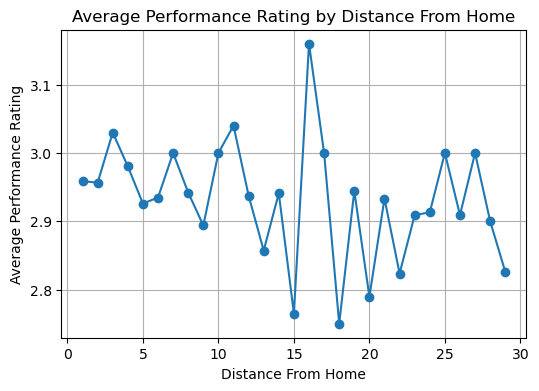

In [55]:
plt.figure(figsize=(6,4))

plt.plot(
    distance_performance.index,
    distance_performance.values,
    marker="o"
)

plt.title("Average Performance Rating by Distance From Home")
plt.xlabel("Distance From Home")
plt.ylabel("Average Performance Rating")

plt.grid(True)
plt.show()

###  Employee Hourly Rate vs Performance Rating

In [56]:
hourlyrate_performance = (
    df.groupby("EmpHourlyRate")["PerformanceRating"]
    .mean()
    .sort_index()
)

hourlyrate_performance

EmpHourlyRate
30     3.153846
31     2.769231
32     3.000000
33     2.937500
34     2.833333
         ...   
96     2.909091
97     2.944444
98     2.800000
99     2.684211
100    2.928571
Name: PerformanceRating, Length: 71, dtype: float64

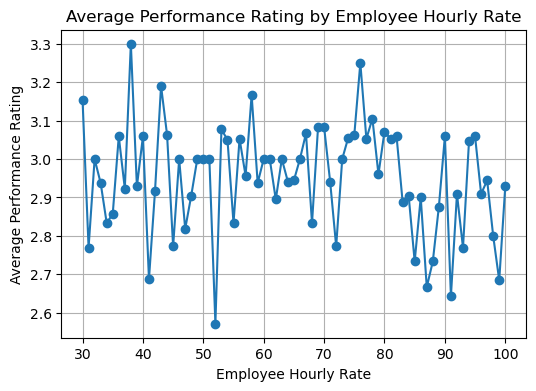

In [57]:
plt.figure(figsize=(6,4))

plt.plot(
    hourlyrate_performance.index,
    hourlyrate_performance.values,
    marker="o"
)

plt.title("Average Performance Rating by Employee Hourly Rate")
plt.xlabel("Employee Hourly Rate")
plt.ylabel("Average Performance Rating")

plt.grid(True)
plt.show()

###  Number of Companies Worked vs Performance Rating

In [58]:
companies_performance = (
    df.groupby("NumCompaniesWorked")["PerformanceRating"]
    .mean()
    .sort_index()
)

companies_performance

NumCompaniesWorked
0    2.897436
1    2.942263
2    2.910569
3    2.962406
4    3.084112
5    2.962264
6    2.982143
7    2.950000
8    2.950000
9    2.846154
Name: PerformanceRating, dtype: float64

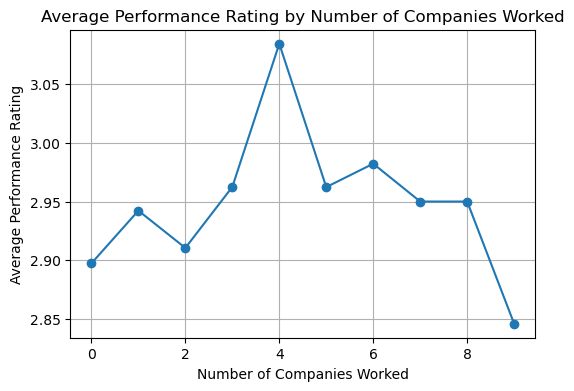

In [59]:
plt.figure(figsize=(6,4))

plt.plot(
    companies_performance.index,
    companies_performance.values,
    marker="o"
)

plt.title("Average Performance Rating by Number of Companies Worked")
plt.xlabel("Number of Companies Worked")
plt.ylabel("Average Performance Rating")

plt.grid(True)
plt.show()

### Correlation Analysis of Numerical Factors vs Performance Rating

In [60]:
numeric_corr = df.select_dtypes(include="number").corr()

performance_corr = (
    numeric_corr["PerformanceRating"]
    .sort_values(ascending=False)
)

performance_corr

PerformanceRating               1.000000
EmpEnvironmentSatisfaction      0.395561
EmpLastSalaryHikePercent        0.333722
EmpWorkLifeBalance              0.124429
NumCompaniesWorked              0.020980
EmpEducationLevel               0.020529
EmpJobSatisfaction              0.000606
TrainingTimesLastYear          -0.005443
EmpJobInvolvement              -0.010539
EmpRelationshipSatisfaction    -0.019502
Age                            -0.040164
EmpHourlyRate                  -0.043116
DistanceFromHome               -0.046142
TotalWorkExperienceInYears     -0.068141
EmpJobLevel                    -0.076632
ExperienceYearsAtThisCompany   -0.111645
YearsWithCurrManager           -0.122313
ExperienceYearsInCurrentRole   -0.147638
YearsSinceLastPromotion        -0.167629
Name: PerformanceRating, dtype: float64

# Correlation heatmap

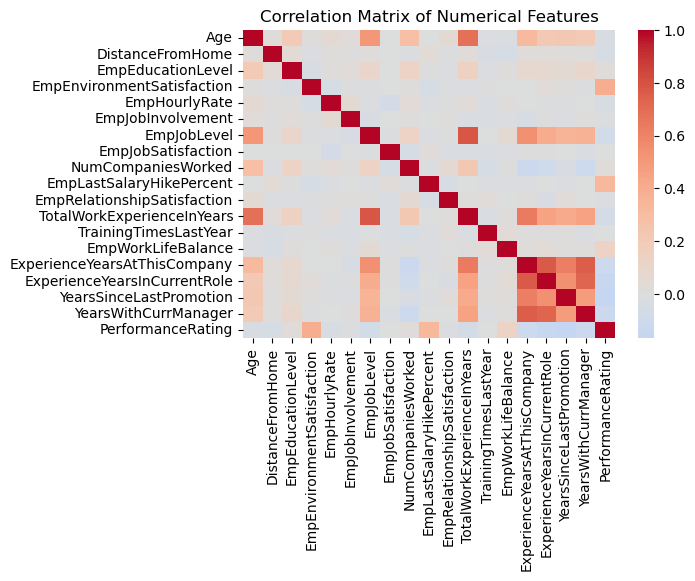

In [61]:
plt.figure(figsize=(6,4))

sns.heatmap(
    numeric_corr,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")
plt.show()

# Data Preprocessing

## Separate Features and Target

In [62]:
X = df.drop("PerformanceRating", axis=1)
y = df["PerformanceRating"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1200, 28)
Target shape: (1200,)


In [63]:
X = X.drop(
    ["EmpNumber", "Age_Group", "Experience_Group"],
    axis=1,
    errors="ignore"
)

print("Features shape after removing unnecessary columns:", X.shape)

Features shape after removing unnecessary columns: (1200, 26)


## Identify numerical and categorical columns

In [64]:
numeric_features = X.select_dtypes(include="number").columns
categorical_features = X.select_dtypes(include="object").columns

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
Index(['Age', 'DistanceFromHome', 'EmpEducationLevel',
       'EmpEnvironmentSatisfaction', 'EmpHourlyRate', 'EmpJobInvolvement',
       'EmpJobLevel', 'EmpJobSatisfaction', 'NumCompaniesWorked',
       'EmpLastSalaryHikePercent', 'EmpRelationshipSatisfaction',
       'TotalWorkExperienceInYears', 'TrainingTimesLastYear',
       'EmpWorkLifeBalance', 'ExperienceYearsAtThisCompany',
       'ExperienceYearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='object')

Categorical features:
Index(['Gender', 'EducationBackground', 'MaritalStatus', 'EmpDepartment',
       'EmpJobRole', 'BusinessTravelFrequency', 'OverTime', 'Attrition'],
      dtype='object')


## Remove Attrition

In [65]:
X = X.drop("Attrition", axis=1)

print("Features shape:", X.shape)

Features shape: (1200, 25)


In [66]:
categorical_features = X.select_dtypes(include="object").columns

print("Categorical features:")
print(categorical_features)

Categorical features:
Index(['Gender', 'EducationBackground', 'MaritalStatus', 'EmpDepartment',
       'EmpJobRole', 'BusinessTravelFrequency', 'OverTime'],
      dtype='object')


##  One-Hot Encoding

In [67]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_encoded = encoder.fit_transform(X[categorical_features])

print("Encoded data shape:", X_encoded.shape)

Encoded data shape: (1200, 41)


##  Combine Numerical and Encoded Categorical Features

In [68]:
X_numeric = X[numeric_features].reset_index(drop=True)

X_encoded_df = pd.DataFrame(
    X_encoded,
    columns=encoder.get_feature_names_out(categorical_features)
)

X_encoded_df = X_encoded_df.reset_index(drop=True)

X_final = pd.concat(
    [X_numeric, X_encoded_df],
    axis=1
)

print("Final feature shape:", X_final.shape)

Final feature shape: (1200, 59)


#  Train-Test Split

In [69]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_final,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (960, 59)
X_test shape: (240, 59)
y_train shape: (960,)
y_test shape: (240,)


# Feature Scaling

In [70]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (960, 59)
X_test_scaled shape: (240, 59)


# Baseline Logistic Regression Model

In [71]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

y_pred_logistic = logistic_model.predict(X_test_scaled)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [72]:
y_pred_logistic[:10]

array([3, 3, 3, 2, 3, 3, 3, 3, 3, 3])

## Evaluate Logistic Regression

In [73]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred_logistic)

precision = precision_score(
    y_test,
    y_pred_logistic,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred_logistic,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred_logistic,
    average="weighted"
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.825
Precision: 0.8165536347517731
Recall   : 0.825
F1 Score : 0.8177380608962194


In [74]:
print(classification_report(y_test, y_pred_logistic))

              precision    recall  f1-score   support

           2       0.62      0.51      0.56        39
           3       0.86      0.93      0.89       175
           4       0.80      0.62      0.70        26

    accuracy                           0.82       240
   macro avg       0.76      0.68      0.72       240
weighted avg       0.82      0.82      0.82       240



**Classification Report:**  

The Logistic Regression model performs best for Performance Rating 3, with a precision of 0.86, recall of 0.93, and F1-score of 0.89. 

For Rating 2, the recall is 0.51, indicating that the model does not correctly identify all employees belonging to this class. For Rating 4, the recall is 0.62, meaning some high-performing employees are also misclassified.

The weighted F1-score is 0.82. Therefore, Logistic Regression provides a good baseline, but other models should be evaluated to determine whether employee performance prediction can be improved.

# Confusion Matrix

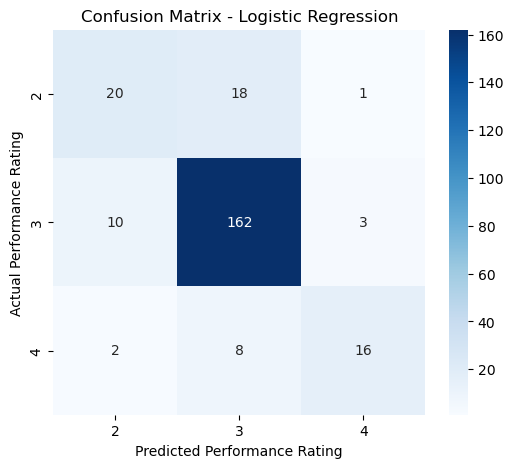

In [75]:
cm = confusion_matrix(y_test, y_pred_logistic)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Performance Rating")
plt.ylabel("Actual Performance Rating")
plt.show()

**Confusion Matrix:**  

The confusion matrix shows that the Logistic Regression model correctly predicts 20 employees with Performance Rating 2, 162 employees with Rating 3, and 16 employees with Rating 4.

The model performs best for Rating 3 because it is the majority class in the dataset. However, several Rating 2 and Rating 4 employees are classified as Rating 3. This indicates that the model has difficulty distinguishing the minority performance classes from the majority class.

# Decision Tree Model

In [76]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    random_state=42
)

decision_tree.fit(X_train, y_train)

y_pred_tree = decision_tree.predict(X_test)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [77]:
y_pred_tree[:10]

array([3, 3, 3, 3, 3, 3, 2, 3, 3, 3])

## Evaluate Decision Tree

In [78]:
accuracy_tree = accuracy_score(y_test, y_pred_tree)

precision_tree = precision_score(
    y_test,
    y_pred_tree,
    average="weighted"
)

recall_tree = recall_score(
    y_test,
    y_pred_tree,
    average="weighted"
)

f1_tree = f1_score(
    y_test,
    y_pred_tree,
    average="weighted"
)

print("Accuracy :", accuracy_tree)
print("Precision:", precision_tree)
print("Recall   :", recall_tree)
print("F1 Score :", f1_tree)

Accuracy : 0.8916666666666667
Precision: 0.8915230429292929
Recall   : 0.8916666666666667
F1 Score : 0.8914300311346726


In [79]:
print(classification_report(y_test, y_pred_tree))

              precision    recall  f1-score   support

           2       0.78      0.79      0.78        39
           3       0.93      0.93      0.93       175
           4       0.83      0.77      0.80        26

    accuracy                           0.89       240
   macro avg       0.84      0.83      0.84       240
weighted avg       0.89      0.89      0.89       240



**Classification Report:**  

The Decision Tree model performs well across all three performance-rating classes. It achieves an F1-score of 0.78 for Rating 2, 0.93 for Rating 3, and 0.80 for Rating 4.

Compared with Logistic Regression, the Decision Tree provides better class-wise performance, particularly for the minority classes Rating 2 and Rating 4. The macro F1-score of 0.84 indicates that the model performs reasonably well across all classes.

Therefore, the Decision Tree is currently a stronger model than Logistic Regression. However, additional models will be evaluated before selecting the final model.

## Decision Tree Confusion Matrix

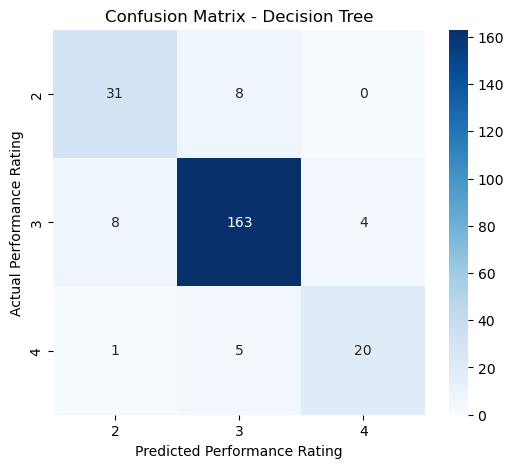

In [80]:
cm_tree = confusion_matrix(y_test, y_pred_tree)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Performance Rating")
plt.ylabel("Actual Performance Rating")
plt.show()

**Confusion Matrix:**  

The Decision Tree correctly predicts 31 employees with Performance Rating 2, 163 employees with Rating 3, and 20 employees with Rating 4.

The model performs well across all three classes. Most misclassifications occur between neighboring performance ratings, particularly between Ratings 2 and 3 and between Ratings 3 and 4.

Compared with Logistic Regression, the Decision Tree shows improved classification of both lower- and higher-performing employees.

# Random Forest

In [81]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [82]:
y_pred_rf[:10]

array([3, 3, 3, 2, 3, 3, 2, 3, 3, 3])

In [83]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)

precision_rf = precision_score(
    y_test,
    y_pred_rf,
    average="weighted"
)

recall_rf = recall_score(
    y_test,
    y_pred_rf,
    average="weighted"
)

f1_rf = f1_score(
    y_test,
    y_pred_rf,
    average="weighted"
)

print("Accuracy :", accuracy_rf)
print("Precision:", precision_rf)
print("Recall   :", recall_rf)
print("F1 Score :", f1_rf)

Accuracy : 0.925
Precision: 0.9275821237585944
Recall   : 0.925
F1 Score : 0.9220866647662228


In [84]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           2       0.91      0.82      0.86        39
           3       0.92      0.98      0.95       175
           4       1.00      0.69      0.82        26

    accuracy                           0.93       240
   macro avg       0.94      0.83      0.88       240
weighted avg       0.93      0.93      0.92       240



**Classification Report:**  

The Random Forest model performs well across all three Performance Rating classes. It achieves an F1-score of 0.86 for Rating 2, 0.95 for Rating 3, and 0.82 for Rating 4.

The model performs particularly well for Rating 3, with a recall of 0.98. For Rating 4, the precision is 1.00, indicating that the employees predicted as Rating 4 are correctly classified, although the recall of 0.69 shows that some actual Rating 4 employees are missed.

The macro F1-score is 0.88 and the weighted F1-score is 0.92. Overall, Random Forest is currently the best-performing model among the models evaluated.

## Random Forest Confusion Matrix

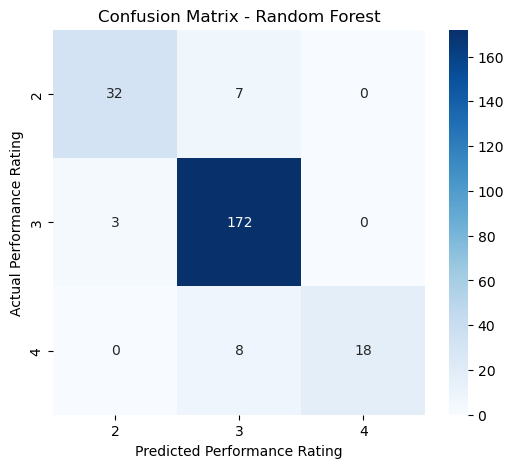

In [85]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Performance Rating")
plt.ylabel("Actual Performance Rating")
plt.show()

## Gradient Boosting Classifier

In [86]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting = GradientBoostingClassifier(random_state=42)
gradient_boosting.fit(X_train, y_train)
y_pred_gb = gradient_boosting.predict(X_test)
y_pred_gb[:10]

array([3, 3, 3, 2, 3, 3, 2, 3, 3, 3])

In [87]:
gb_accuracy = accuracy_score(y_test, y_pred_gb)
gb_precision = precision_score(y_test, y_pred_gb, average="weighted")
gb_recall = recall_score(y_test, y_pred_gb, average="weighted")
gb_f1 = f1_score(y_test, y_pred_gb, average="weighted")

print("Gradient Boosting Accuracy:", gb_accuracy)
print("Gradient Boosting Precision:", gb_precision)
print("Gradient Boosting Recall:", gb_recall)
print("Gradient Boosting F1 Score:", gb_f1)

Gradient Boosting Accuracy: 0.9333333333333333
Gradient Boosting Precision: 0.9334220103666163
Gradient Boosting Recall: 0.9333333333333333
Gradient Boosting F1 Score: 0.9321002061529194


In [88]:
print(classification_report(y_test, y_pred_gb))

              precision    recall  f1-score   support

           2       0.89      0.87      0.88        39
           3       0.94      0.97      0.96       175
           4       0.95      0.77      0.85        26

    accuracy                           0.93       240
   macro avg       0.93      0.87      0.90       240
weighted avg       0.93      0.93      0.93       240



## XGBoost Classifier

In [89]:
from xgboost import XGBClassifier

In [90]:
xgb_model = XGBClassifier(
    n_estimators=200,
    random_state=42,
    eval_metric="mlogloss"
)

In [91]:
y_train_xgb = y_train - 2
y_test_xgb = y_test - 2

In [92]:
xgb_model.fit(X_train, y_train_xgb)

,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'mlogloss'


In [93]:
y_pred_xgb = xgb_model.predict(X_test)

In [94]:
y_pred_xgb = y_pred_xgb + 2

In [95]:
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb, average="weighted")
xgb_recall = recall_score(y_test, y_pred_xgb, average="weighted")
xgb_f1 = f1_score(y_test, y_pred_xgb, average="weighted")

print("XGBoost Accuracy:", xgb_accuracy)
print("XGBoost Precision:", xgb_precision)
print("XGBoost Recall:", xgb_recall)
print("XGBoost F1 Score:", xgb_f1)

XGBoost Accuracy: 0.9208333333333333
XGBoost Precision: 0.9201986076986076
XGBoost Recall: 0.9208333333333333
XGBoost F1 Score: 0.9184027777777778


In [96]:
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           2       0.91      0.77      0.83        39
           3       0.92      0.98      0.95       175
           4       0.91      0.77      0.83        26

    accuracy                           0.92       240
   macro avg       0.91      0.84      0.87       240
weighted avg       0.92      0.92      0.92       240



##  Model Comparison

In [97]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb),
        accuracy_score(y_test, y_pred_xgb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_logistic, average="weighted"),
        precision_score(y_test, y_pred_tree, average="weighted"),
        precision_score(y_test, y_pred_rf, average="weighted"),
        precision_score(y_test, y_pred_gb, average="weighted"),
        precision_score(y_test, y_pred_xgb, average="weighted")
    ],
    "Recall": [
        recall_score(y_test, y_pred_logistic, average="weighted"),
        recall_score(y_test, y_pred_tree, average="weighted"),
        recall_score(y_test, y_pred_rf, average="weighted"),
        recall_score(y_test, y_pred_gb, average="weighted"),
        recall_score(y_test, y_pred_xgb, average="weighted")
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_logistic, average="weighted"),
        f1_score(y_test, y_pred_tree, average="weighted"),
        f1_score(y_test, y_pred_rf, average="weighted"),
        f1_score(y_test, y_pred_gb, average="weighted"),
        f1_score(y_test, y_pred_xgb, average="weighted")
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.825000,0.816554,0.825000,0.817738
1,Decision Tree,0.891667,0.891523,0.891667,0.891430
2,Random Forest,0.925000,0.927582,0.925000,0.922087
3,Gradient Boosting,0.933333,0.933422,0.933333,0.932100
4,XGBoost,0.920833,0.920199,0.920833,0.918403


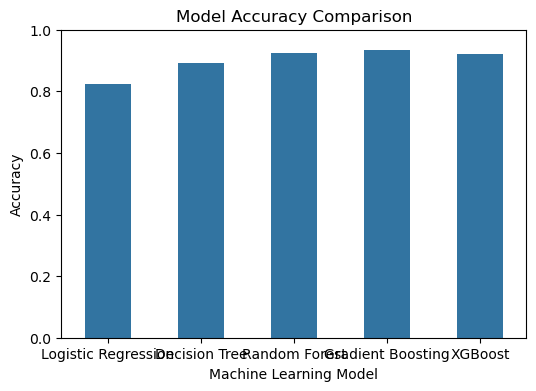

In [98]:
plt.figure(figsize=(6,4))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy",
    width=0.5
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.show()

Five machine learning algorithms were evaluated for employee performance prediction.

Gradient Boosting achieved the highest accuracy of 93.33% and the highest weighted F1-score of 93.21%. Random Forest achieved the second-best performance with an accuracy of 92.50%.

Therefore, Gradient Boosting is selected as the final model for this project.

## Final Model Evaluation – Gradient Boosting

### Confusion Matrix

In [99]:
print(classification_report(y_test, y_pred_gb))

              precision    recall  f1-score   support

           2       0.89      0.87      0.88        39
           3       0.94      0.97      0.96       175
           4       0.95      0.77      0.85        26

    accuracy                           0.93       240
   macro avg       0.93      0.87      0.90       240
weighted avg       0.93      0.93      0.93       240



### Final Performance

In [100]:
print("Final Model: Gradient Boosting")
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb, average="weighted"))
print("Recall:", recall_score(y_test, y_pred_gb, average="weighted"))
print("F1 Score:", f1_score(y_test, y_pred_gb, average="weighted"))

Final Model: Gradient Boosting
Accuracy: 0.9333333333333333
Precision: 0.9334220103666163
Recall: 0.9333333333333333
F1 Score: 0.9321002061529194


Gradient Boosting is the best-performing model among the five evaluated algorithms.

The model achieved an accuracy of 93.33% and a weighted F1-score of 93.21%. It provides strong overall performance for predicting employee performance ratings.

The model performs particularly well for the majority Performance Rating class, while the minority classes require comparatively more attention.

##  Final Feature Importance – Gradient Boosting

In [101]:
gb_feature_importance = pd.DataFrame({
    "Feature": X_final.columns,
    "Importance": gradient_boosting.feature_importances_
})

gb_feature_importance = (
    gb_feature_importance
    .sort_values("Importance", ascending=False)
)

gb_feature_importance.head(10)

,Feature,Importance
3,EmpEnvironmentSatisfaction,0.277289
9,EmpLastSalaryHikePercent,0.243855
16,YearsSinceLastPromotion,0.195365
30,EmpDepartment_Development,0.066741
13,EmpWorkLifeBalance,0.054151
15,ExperienceYearsInCurrentRole,0.043651
17,YearsWithCurrManager,0.015939
38,EmpJobRole_Developer,0.014767
14,ExperienceYearsAtThisCompany,0.011755
4,EmpHourlyRate,0.010162


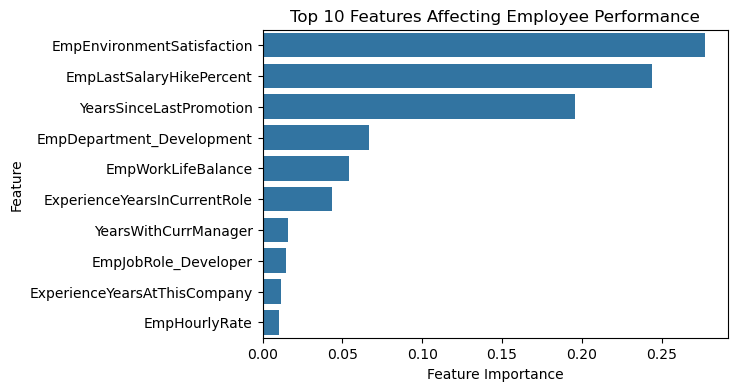

In [102]:
top_gb_features = gb_feature_importance.head(10)

plt.figure(figsize=(6,4))

sns.barplot(
    data=top_gb_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features Affecting Employee Performance")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()

In [103]:
gb_feature_importance.head(10)

,Feature,Importance
3,EmpEnvironmentSatisfaction,0.277289
9,EmpLastSalaryHikePercent,0.243855
16,YearsSinceLastPromotion,0.195365
30,EmpDepartment_Development,0.066741
13,EmpWorkLifeBalance,0.054151
15,ExperienceYearsInCurrentRole,0.043651
17,YearsWithCurrManager,0.015939
38,EmpJobRole_Developer,0.014767
14,ExperienceYearsAtThisCompany,0.011755
4,EmpHourlyRate,0.010162


## Hyperparameter Tuning – Gradient Boosting

In [104]:
from sklearn.model_selection import GridSearchCV

In [105]:
param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

In [106]:
grid_search = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

,estimator,GradientBoost...ndom_state=42)
,param_grid,"{'learning_rate': [0.05, 0.1], 'max_depth': [2, 3], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], ...}"
,scoring,'f1_weighted'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'log_loss'


In [107]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


In [108]:
print("Best Cross-Validation F1 Score:")
print(grid_search.best_score_)

Best Cross-Validation F1 Score:
0.9321178369467074


In [109]:
tuned_gb = grid_search.best_estimator_

## Tuned Gradient Boosting Model Evaluation

In [110]:
y_pred_tuned_gb = tuned_gb.predict(X_test)

In [111]:
print("Tuned Gradient Boosting Performance")
print("Accuracy:", accuracy_score(y_test, y_pred_tuned_gb))
print("Precision:", precision_score(y_test, y_pred_tuned_gb, average="weighted"))
print("Recall:", recall_score(y_test, y_pred_tuned_gb, average="weighted"))
print("F1 Score:", f1_score(y_test, y_pred_tuned_gb, average="weighted"))

Tuned Gradient Boosting Performance
Accuracy: 0.9291666666666667
Precision: 0.928971506635441
Recall: 0.9291666666666667
F1 Score: 0.9274434605174532


In [112]:
print(classification_report(y_test, y_pred_tuned_gb))

              precision    recall  f1-score   support

           2       0.89      0.82      0.85        39
           3       0.93      0.98      0.96       175
           4       0.95      0.77      0.85        26

    accuracy                           0.93       240
   macro avg       0.93      0.86      0.89       240
weighted avg       0.93      0.93      0.93       240



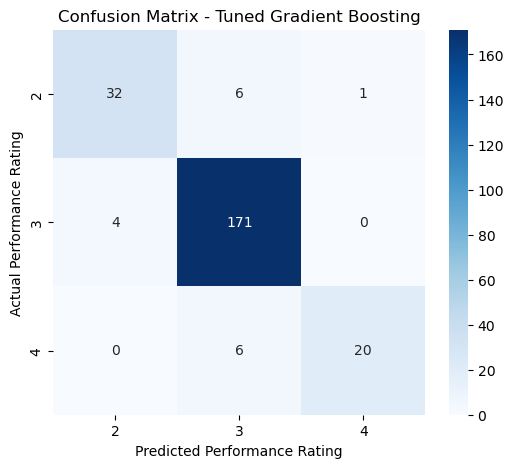

In [113]:
cm_tuned_gb = confusion_matrix(y_test, y_pred_tuned_gb)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_tuned_gb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Confusion Matrix - Tuned Gradient Boosting")
plt.xlabel("Predicted Performance Rating")
plt.ylabel("Actual Performance Rating")
plt.show()

**Interpretation:**

The tuned Gradient Boosting model achieved an overall accuracy of 93% and a weighted F1-score of 93%.

The model performed best for Performance Rating 3, with an F1-score of 0.96. It achieved an F1-score of 0.85 for both Rating 2 and Rating 4.

The macro F1-score of 0.89 indicates that the model performs reasonably well across all performance rating classes.

However, the tuned model did not improve upon the original Gradient Boosting model. Therefore, the original Gradient Boosting model, with an accuracy of 93.33% and weighted F1-score of 93.21%, is selected as the final model.

## Final Model Selection

Five machine learning models were evaluated for predicting employee performance.

| Model | Accuracy | Weighted F1 Score |
|---|---:|---:|
| Logistic Regression | 82.50% | 81.77% |
| Decision Tree | 89.17% | 89.14% |
| Random Forest | 92.50% | 92.21% |
| Gradient Boosting | **93.33%** | **93.21%** |
| XGBoost | 92.08% | 91.84% |
| Tuned Gradient Boosting | 92.92% | 92.74% |

The **original Gradient Boosting model** achieved the highest test accuracy of **93.33%** and the highest weighted F1-score of **93.21%**.

Therefore, **Gradient Boosting is selected as the final model** for predicting employee performance.

The model provides strong predictive performance across the three performance rating classes: 2, 3, and 4.

## Top 3 Important Factors Affecting Employee Performance

In [114]:
top_3_factors = gb_feature_importance.head(3)

top_3_factors

,Feature,Importance
3,EmpEnvironmentSatisfaction,0.277289
9,EmpLastSalaryHikePercent,0.243855
16,YearsSinceLastPromotion,0.195365


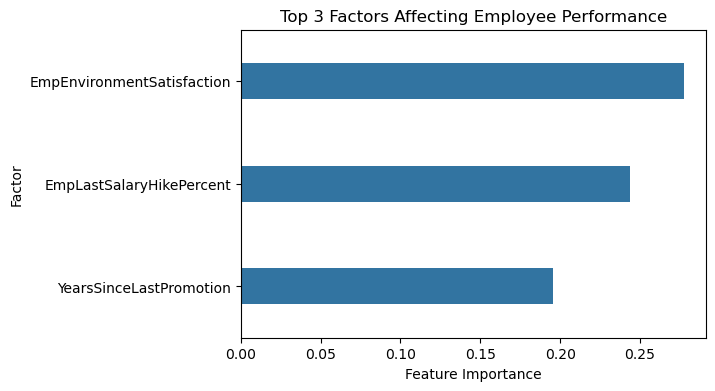

In [115]:
plt.figure(figsize=(6,4))

sns.barplot(
    data=top_3_factors,
    x="Importance",
    y="Feature",
    width=0.35
)

plt.title("Top 3 Factors Affecting Employee Performance")
plt.xlabel("Feature Importance")
plt.ylabel("Factor")
plt.show()

##  Top 3 Important Factors Affecting Employee Performance

The Gradient Boosting model identified the following three factors as the most important contributors to employee performance prediction:

1. **Environment Satisfaction** – Importance: 0.277
2. **Employee Last Salary Hike Percentage** – Importance: 0.244
3. **Years Since Last Promotion** – Importance: 0.195

# Robustness Checks (added after review)

The model was originally chosen using a single train/test split. The checks below verify the result with cross-validation, macro-F1 and a more reliable feature-importance method.

## 5-Fold Stratified Cross-Validation (all models)

In [116]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, random_state=42, eval_metric="mlogloss"),
}
rows = []
for name, m in models.items():
    yy = y - 2 if name == "XGBoost" else y   # XGBoost needs labels starting at 0
    r = cross_validate(m, X_final, yy, cv=skf,
                       scoring=["accuracy", "f1_weighted", "f1_macro"], n_jobs=-1)
    rows.append({"Model": name,
                 "CV Accuracy": r["test_accuracy"].mean(), "Acc Std": r["test_accuracy"].std(),
                 "CV Weighted F1": r["test_f1_weighted"].mean(),
                 "CV Macro F1": r["test_f1_macro"].mean()})
cv_results = pd.DataFrame(rows).sort_values("CV Macro F1", ascending=False)
cv_results

,Model,CV Accuracy,Acc Std,CV Weighted F1,CV Macro F1
3,Gradient Boosting,0.930833,0.014093,0.930610,0.896707
4,XGBoost,0.925833,0.018708,0.925340,0.888527
2,Random Forest,0.922500,0.014337,0.919729,0.872586
1,Decision Tree,0.890833,0.017951,0.891065,0.834343
0,Logistic Regression,0.811667,0.030092,0.806941,0.707952


**Interpretation:** Gradient Boosting has the best 5-fold CV accuracy (0.931 ± 0.014) and the best CV macro-F1 (0.897). The CV accuracy is almost identical to the test-set accuracy (0.933), so the result is stable and not the effect of a lucky train/test split. XGBoost is very close (0.926 accuracy, 0.889 macro-F1) and the gap is within one standard deviation, so Gradient Boosting and XGBoost are practically equal, with Gradient Boosting slightly ahead. Logistic Regression is clearly the weakest model.

## Macro-F1 added to the test-set comparison

In [117]:
from sklearn.metrics import f1_score
preds = {
    "Logistic Regression": y_pred_logistic, "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_rf, "Gradient Boosting": y_pred_gb,
    "XGBoost": y_pred_xgb, "Tuned Gradient Boosting": y_pred_tuned_gb,
}
pd.DataFrame({
    "Model": list(preds),
    "Accuracy": [accuracy_score(y_test, p) for p in preds.values()],
    "Weighted F1": [f1_score(y_test, p, average="weighted") for p in preds.values()],
    "Macro F1": [f1_score(y_test, p, average="macro") for p in preds.values()],
})

,Model,Accuracy,Weighted F1,Macro F1
0,Logistic Regression,0.825000,0.817738,0.717198
1,Decision Tree,0.891667,0.891430,0.837862
2,Random Forest,0.925000,0.922087,0.877774
3,Gradient Boosting,0.933333,0.932100,0.896412
4,XGBoost,0.920833,0.918403,0.872222
5,Tuned Gradient Boosting,0.929167,0.927443,0.886568


## Feature Importance grouped by original column

One-hot encoding splits a single column (e.g. `EmpDepartment`) into many dummy columns, which understates its importance. Here the dummies are summed back to the original column.

EmpEnvironmentSatisfaction      0.277289
EmpLastSalaryHikePercent        0.243855
YearsSinceLastPromotion         0.195365
EmpDepartment                   0.068903
EmpWorkLifeBalance              0.054151
ExperienceYearsInCurrentRole    0.043651
EmpJobRole                      0.024963
YearsWithCurrManager            0.015939
ExperienceYearsAtThisCompany    0.011755
EmpHourlyRate                   0.010162
dtype: float64


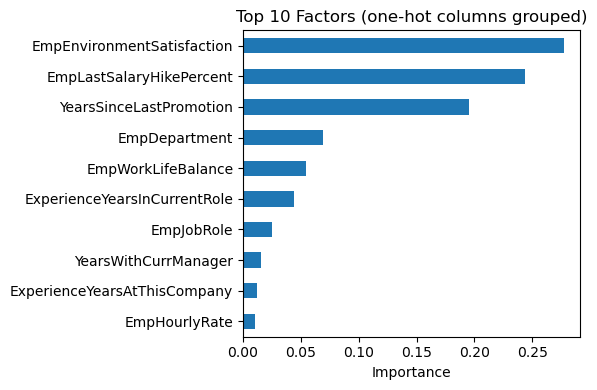

In [118]:
imp = pd.Series(gradient_boosting.feature_importances_, index=X_final.columns)
def original_name(col):
    for cat in categorical_features:
        if col.startswith(cat + "_"):
            return cat
    return col
grouped_importance = imp.groupby(original_name).sum().sort_values(ascending=False)
print(grouped_importance.head(10))
grouped_importance.head(10).sort_values().plot(kind="barh", figsize=(6,4),
    title="Top 10 Factors (one-hot columns grouped)")
plt.xlabel("Importance"); plt.tight_layout(); plt.show()

## Permutation Importance (test set)

Impurity-based importance can favour some features. Permutation importance measures how much accuracy drops when a column is shuffled.

In [119]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(gradient_boosting, X_test, y_test, n_repeats=20,
                            random_state=42, scoring="f1_macro", n_jobs=-1)
perm_importance = pd.Series(pi.importances_mean, index=X_test.columns).groupby(original_name).sum()
perm_importance.sort_values(ascending=False).head(10)

EmpEnvironmentSatisfaction      0.293539
EmpLastSalaryHikePercent        0.268244
YearsSinceLastPromotion         0.096538
EmpDepartment                   0.062255
ExperienceYearsInCurrentRole    0.051805
EmpWorkLifeBalance              0.019987
EmpJobRole                      0.010671
YearsWithCurrManager            0.008757
ExperienceYearsAtThisCompany    0.006422
Age                             0.006044
dtype: float64

**Interpretation:** Both methods give the same top 3 factors: Environment Satisfaction, Last Salary Hike % and Years Since Last Promotion. Environment Satisfaction (0.29) and Salary Hike % (0.27) are very strong under permutation importance. Years Since Last Promotion is still third but weaker (0.10 vs 0.20 in the impurity-based ranking), so it is a less robust factor than the first two. Work-Life Balance drops to 0.02 under permutation importance and should be treated as a secondary factor. Grouping the one-hot columns shows that Department (0.069) is the fourth most important factor.

# Save Final Model


In [120]:
import joblib

In [121]:
joblib.dump(
    gradient_boosting,
    "gradient_boosting_model.pkl"
)

['gradient_boosting_model.pkl']

In [122]:
joblib.dump(
    encoder,
    "encoder.pkl"
)

['encoder.pkl']

In [123]:
joblib.dump(
    X_final.columns.tolist(),
    "feature_columns.pkl"
)

['feature_columns.pkl']

In [124]:
import joblib

loaded_model = joblib.load("gradient_boosting_model.pkl")

print("Model loaded successfully!")
print(type(loaded_model))

Model loaded successfully!
<class 'sklearn.ensemble._gb.GradientBoostingClassifier'>


In [125]:
loaded_encoder = joblib.load("encoder.pkl")

print("Encoder loaded successfully!")
print(type(loaded_encoder))

Encoder loaded successfully!
<class 'sklearn.preprocessing._encoders.OneHotEncoder'>


In [126]:
loaded_columns = joblib.load("feature_columns.pkl")

print("Feature columns loaded successfully!")
print("Total features:", len(loaded_columns))
print("First 5 features:", loaded_columns[:5])

Feature columns loaded successfully!
Total features: 59
First 5 features: ['Age', 'DistanceFromHome', 'EmpEducationLevel', 'EmpEnvironmentSatisfaction', 'EmpHourlyRate']


In [127]:
y_pred_saved = loaded_model.predict(X_test)

print("Predictions generated successfully!")
print("First 10 actual ratings:", y_test.iloc[:10].tolist())
print("First 10 predicted ratings:", y_pred_saved[:10].tolist())

Predictions generated successfully!
First 10 actual ratings: [3, 3, 2, 2, 3, 3, 2, 3, 3, 3]
First 10 predicted ratings: [3, 3, 3, 2, 3, 3, 2, 3, 3, 3]


In [128]:
from sklearn.metrics import accuracy_score

saved_model_accuracy = accuracy_score(y_test, y_pred_saved)

print("Saved Model Accuracy:", round(saved_model_accuracy * 100, 2), "%")

Saved Model Accuracy: 93.33 %


### Model Saving and Validation Summary

The original Gradient Boosting Classifier was selected as the final model because it achieved the best performance among the evaluated models.

The final model was saved successfully as `gradient_boosting_model.pkl`. The OneHotEncoder was saved as `encoder.pkl`, and the feature column names were saved as `feature_columns.pkl`.

All three files were loaded successfully. The saved model generated predictions on the test dataset and achieved an accuracy of **93.33%**, confirming that the saved model works correctly.



## Reusable prediction function

In [129]:
def predict_performance(new_df):
    """Predict PerformanceRating for new employee rows (same columns as the original data,
    without PerformanceRating)."""
    d = new_df.drop(columns=["EmpNumber", "Attrition", "Age_Group", "Experience_Group"], errors="ignore")
    num = d[list(numeric_features)].reset_index(drop=True)
    cat = pd.DataFrame(loaded_encoder.transform(d[list(categorical_features)]),
                       columns=loaded_encoder.get_feature_names_out(list(categorical_features)))
    X_new = pd.concat([num, cat], axis=1)[loaded_columns]
    return loaded_model.predict(X_new)

# Example: predict_performance(df.drop(columns="PerformanceRating").head())

In [130]:
# Test the prediction function on 10 existing employees
sample = df.drop(columns="PerformanceRating").head(10)
print("Actual   :", df["PerformanceRating"].head(10).tolist())
print("Predicted:", predict_performance(sample).tolist())

Actual   : [3, 3, 4, 3, 3, 4, 3, 3, 3, 3]
Predicted: [3, 3, 4, 3, 3, 4, 3, 3, 3, 3]


## Recommendations to Improve Employee Performance

These recommendations are based on the top factors found by Gradient Boosting (confirmed by permutation importance) and the patterns seen in the EDA. They describe associations, not proven causes.

| Priority | Factor | Evidence in the data | Recommended action |
|---|---|---|---|
| 1 | Environment Satisfaction | Average rating about 2.66 when satisfaction is 1-2, versus about 3.14 when it is 3-4. Top factor in both importance methods. | Survey low-satisfaction teams and fix workplace issues first. |
| 2 | Last Salary Hike % | Correlation +0.33 with rating; second factor in both importance methods. | Link salary hikes transparently to performance and review pay for low-hike groups. |
| 3 | Years Since Last Promotion | Average rating falls from about 3.12 (promoted recently) to about 2.76 (2-4 years without promotion). Third factor, but less robust under permutation importance. | Hold career-path and promotion reviews for employees stalled for 2+ years. |
| 4 | Department | Finance (2.78) and Sales (2.86) have the lowest average rating; Development (3.09) the highest. | Give targeted support and training to Finance and Sales. |
| 5 | Work-Life Balance (secondary) | Rating 1 gives 2.75 average, rating 4 gives 3.12, but importance is low in the model. | Monitor workload and overtime; offer flexible working options. |

**Limitations:** The data is observational. For example, a higher salary hike may be the result of good performance rather than its cause. The recommendations should therefore be tested through small pilot programs before a company-wide rollout. The model is also weaker on the minority classes (Rating 4 recall is 77%).

## Conclusion

This project analyzed employee performance at INX Future Inc. using Exploratory Data Analysis (EDA) and machine learning. Performance ratings were compared across departments (Development and Data Science rate highest; Finance and Sales lowest), and the factors most associated with performance were identified.

Five models were compared. The Gradient Boosting Classifier was selected as the final model. It achieved 93.33% accuracy and a macro-F1 of 0.896 on the test set, and 0.931 accuracy and a macro-F1 of 0.897 in 5-fold cross-validation. The close match between test and CV scores shows that the model is stable. XGBoost performed almost equally well. The model is weaker on the minority classes, with a recall of 77% for Rating 4.

The top three factors, confirmed by both feature importance and permutation importance, are **Environment Satisfaction**, **Last Salary Hike Percentage** and **Years Since Last Promotion**. The third factor is less robust than the first two. Department is the next most important factor.

INX Future Inc. should improve the work environment, link salary hikes to performance, review long-stalled promotions and support the lowest-rated departments (Finance and Sales). Since the findings show association and not causation, these actions should first be tested with pilot programs. This should help address the decline in performance and, through it, client satisfaction.